# Capibara / RWB: схема → первичный EDA → предобработка → повторный EDA

**Назначение:** проверяемый исследовательский результат для чек-поинта и материал для презентации.
Это собственный ноутбук на восьми локальных CSV, а не запуск стороннего кода.
Он не меняет CSV и PostgreSQL; преобразования выполняются в копиях DataFrame.
**Финальные ответы хакатона впоследствии должны считаться из SQL-модели core/mart.**

Маршрут: 1) вход и схема; 2) исходные пропуски/ключи/ссылки; 3) правила обработки;
4) типизированные копии; 5) безопасные агрегаты; 6) повторные проверки и пять контролей;
7) графики; 8) ограничения и следующие шаги.

Деньги для точной сверки хранятся в целых сотых единицы исходной валюты (`*_cents`),
в целевом PostgreSQL им соответствует точный `numeric`, а не `float`.
Геолокация, маркетинговые лиды и корзины в данном пакете отсутствуют.

## 1. Окружение и воспроизводимость
Запускать целиком с чистого ядра, из корня проекта или папки notebooks.
Не требуются интернет, Kaggle API и подключение к базе после установки зависимостей.
Артефакты сохраняются в `output/checkpoint/eda/`, исходники не перезаписываются.

In [1]:
from pathlib import Path
from decimal import Decimal, ROUND_HALF_UP
import hashlib, json, platform, re, sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'data/olist_orders_dataset.csv').is_file()), None)
assert ROOT is not None, 'Запустите из корня rwb_hack или папки notebooks'
DATA = ROOT/'data'
OUT = ROOT/'output/checkpoint/eda'
FIG = OUT/'figures'; TABLE = OUT/'tables'
FIG.mkdir(parents=True, exist_ok=True); TABLE.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 25)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'axes.titlepad':14,'figure.facecolor':'white','svg.fonttype':'none'})
BLUE='#2364A6'; ORANGE='#D98736'; GRAY='#93A5B8'
artifacts=[]
def savefig(fig, name, caption):
    fig.tight_layout()
    fig.savefig(FIG/f'{name}.png',dpi=170,bbox_inches='tight',facecolor='white')
    fig.savefig(FIG/f'{name}.svg',bbox_inches='tight',facecolor='white')
    display(Image(filename=str(FIG/f'{name}.png')))
    display(Markdown(caption))
    artifacts.append({'id':name,'png':f'figures/{name}.png','svg':f'figures/{name}.svg','caption':caption})
    plt.close(fig)
def save_table(df, name):
    df.to_csv(TABLE/f'{name}.csv',index=False,encoding='utf-8-sig')
def amount(cents): return Decimal(int(cents))/100
print({'python':platform.python_version(),'pandas':pd.__version__,
       'numpy':np.__version__,'matplotlib':matplotlib.__version__})

{'python': '3.12.14', 'pandas': '2.3.3', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}


## 2. Входные файлы и зерно таблиц
Зерно — смысл одной строки. У позиции, платежа и заказа оно различается.
Все исходные поля читаем строками; пустые значения — отдельные NA.
`keep_default_na=False` не превращает допустимый текстовый код в пропуск по догадке библиотеки.

In [2]:
FILES={
 'orders':'olist_orders_dataset.csv', 'order_items':'olist_order_items_dataset.csv',
 'order_payments':'olist_order_payments_dataset.csv','order_reviews':'olist_order_reviews_dataset.csv',
 'products':'olist_products_dataset.csv','sellers':'olist_sellers_dataset.csv',
 'customers':'olist_customers_dataset.csv','product_category_translation':'product_category_name_translation.csv'}
KEYS={'orders':['order_id'],'order_items':['order_id','order_item_id'],
      'order_payments':['order_id','payment_sequential'],'order_reviews':['review_id','order_id'],
      'products':['product_id'],'sellers':['seller_id'],'customers':['customer_id'],
      'product_category_translation':['product_category_name']}
GRAIN={'orders':'заказ','order_items':'позиция товара в заказе',
       'order_payments':'платежная запись заказа','order_reviews':'связь отзыва с заказом',
       'products':'карточка товара','sellers':'продавец','customers':'контекст покупателя',
       'product_category_translation':'перевод категории'}
EXPECTED={'orders':99441,'order_items':112650,'order_payments':103886,'order_reviews':99224,
          'products':32951,'sellers':3095,'customers':99441,'product_category_translation':71}
hashes_before={name:hashlib.sha256((DATA/file).read_bytes()).hexdigest() for name,file in FILES.items()}
raw={name:pd.read_csv(DATA/file,dtype='string',encoding='utf-8-sig',
                     keep_default_na=False,na_values=['']) for name,file in FILES.items()}
schema=pd.DataFrame([{'table':name,'rows':len(df),'columns':len(df.columns),
                      'grain':GRAIN[name],'key':' + '.join(KEYS[name]),
                      'key_null_rows':int(df[KEYS[name]].isna().any(axis=1).sum()),
                      'duplicate_key_rows':int(df.duplicated(KEYS[name]).sum()),
                      'full_duplicate_rows':int(df.duplicated().sum())} for name,df in raw.items()])
display(schema); save_table(schema,'01_raw_schema')
assert sum(len(df) for df in raw.values())==550759
for name,n in EXPECTED.items(): assert len(raw[name])==n, name
assert schema.key_null_rows.sum()==0 and schema.duplicate_key_rows.sum()==0
print('Колонки orders:',list(raw['orders'].columns))
print('review_id уникален:',raw['order_reviews']['review_id'].is_unique,
      '; пара review_id/order_id уникальна:',not raw['order_reviews'].duplicated(KEYS['order_reviews']).any())

,table,rows,columns,grain,key,key_null_rows,duplicate_key_rows,full_duplicate_rows
0,orders,99441,8,заказ,order_id,0,0,0
1,order_items,112650,7,позиция товара в заказе,order_id + order_item_id,0,0,0
2,order_payments,103886,5,платежная запись заказа,order_id + payment_sequential,0,0,0
3,order_reviews,99224,7,связь отзыва с заказом,review_id + order_id,0,0,0
4,products,32951,9,карточка товара,product_id,0,0,0
5,sellers,3095,4,продавец,seller_id,0,0,0
6,customers,99441,5,контекст покупателя,customer_id,0,0,0
7,product_category_translation,71,2,перевод категории,product_category_name,0,0,0


Колонки orders: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
review_id уникален: False ; пара review_id/order_id уникальна: True


## 3. Первичный EDA: размеры, пропуски и статусы
Большое число NULL в тексте отзыва допустимо. Пропуск даты или категории требует
описанного правила, а не автоматического удаления заказа.

,table,column,missing,missing_pct,distinct
23,order_reviews,review_comment_title,87656,88.341530,4527
24,order_reviews,review_comment_message,58247,58.702532,36159
6,orders,order_delivered_customer_date,2965,2.981668,95664
29,products,product_name_lenght,610,1.851234,66
28,products,product_category_name,610,1.851234,73
30,products,product_description_lenght,610,1.851234,2960
31,products,product_photos_qty,610,1.851234,19
5,orders,order_delivered_carrier_date,1783,1.793023,81018
4,orders,order_approved_at,160,0.160899,90733
32,products,product_weight_g,2,0.006070,2204


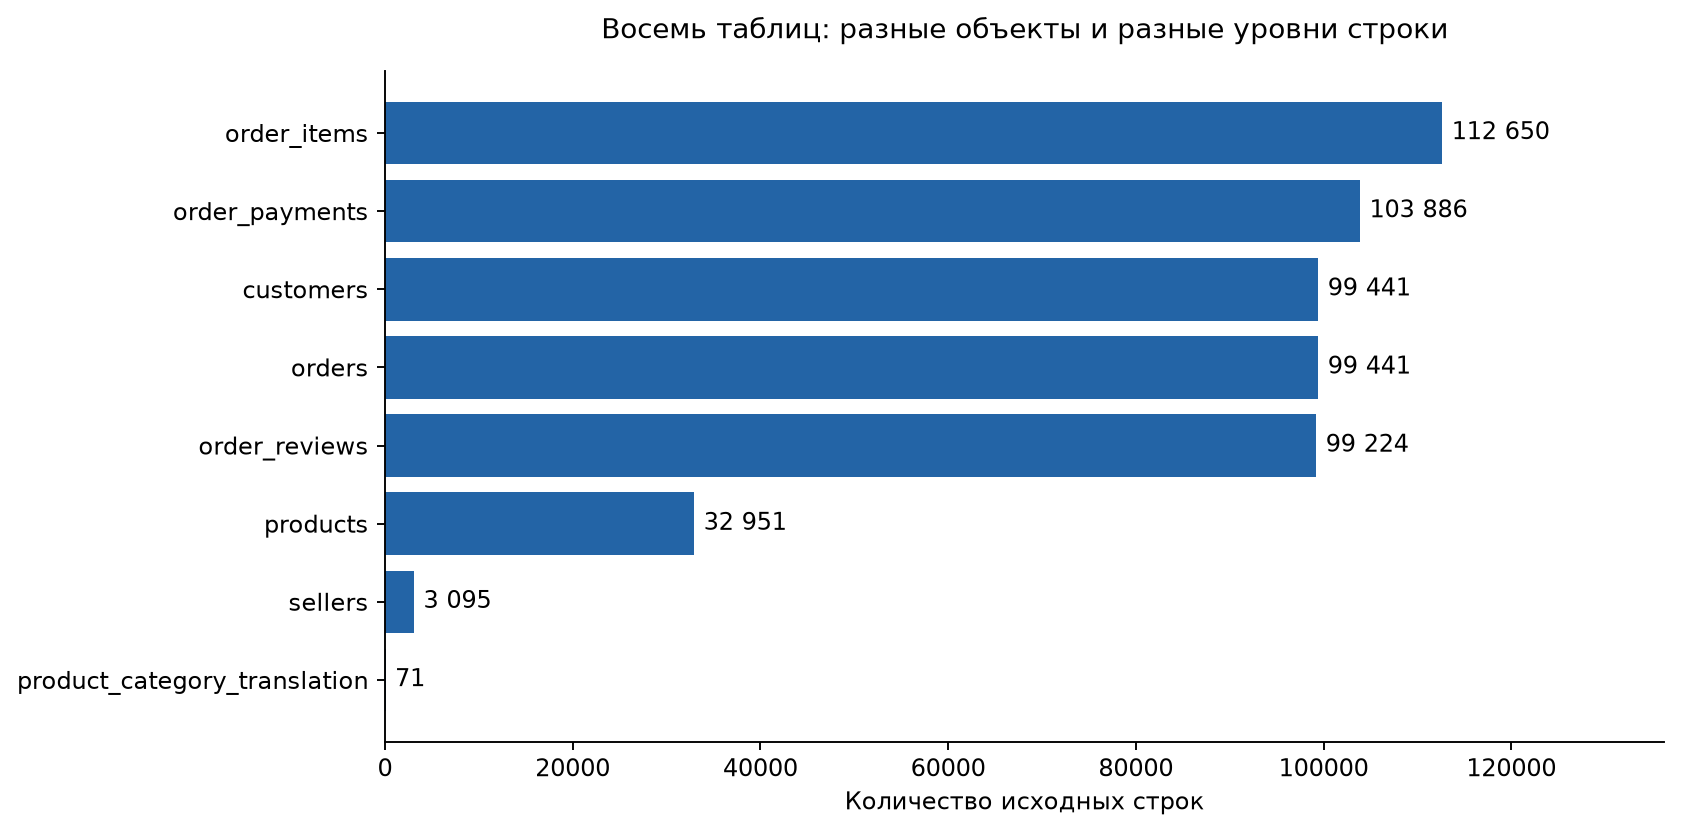

**Вывод:** 99 441 заказ не равен 112 650 позициям. Это ожидаемая разница зерна, а не дубли заказов.

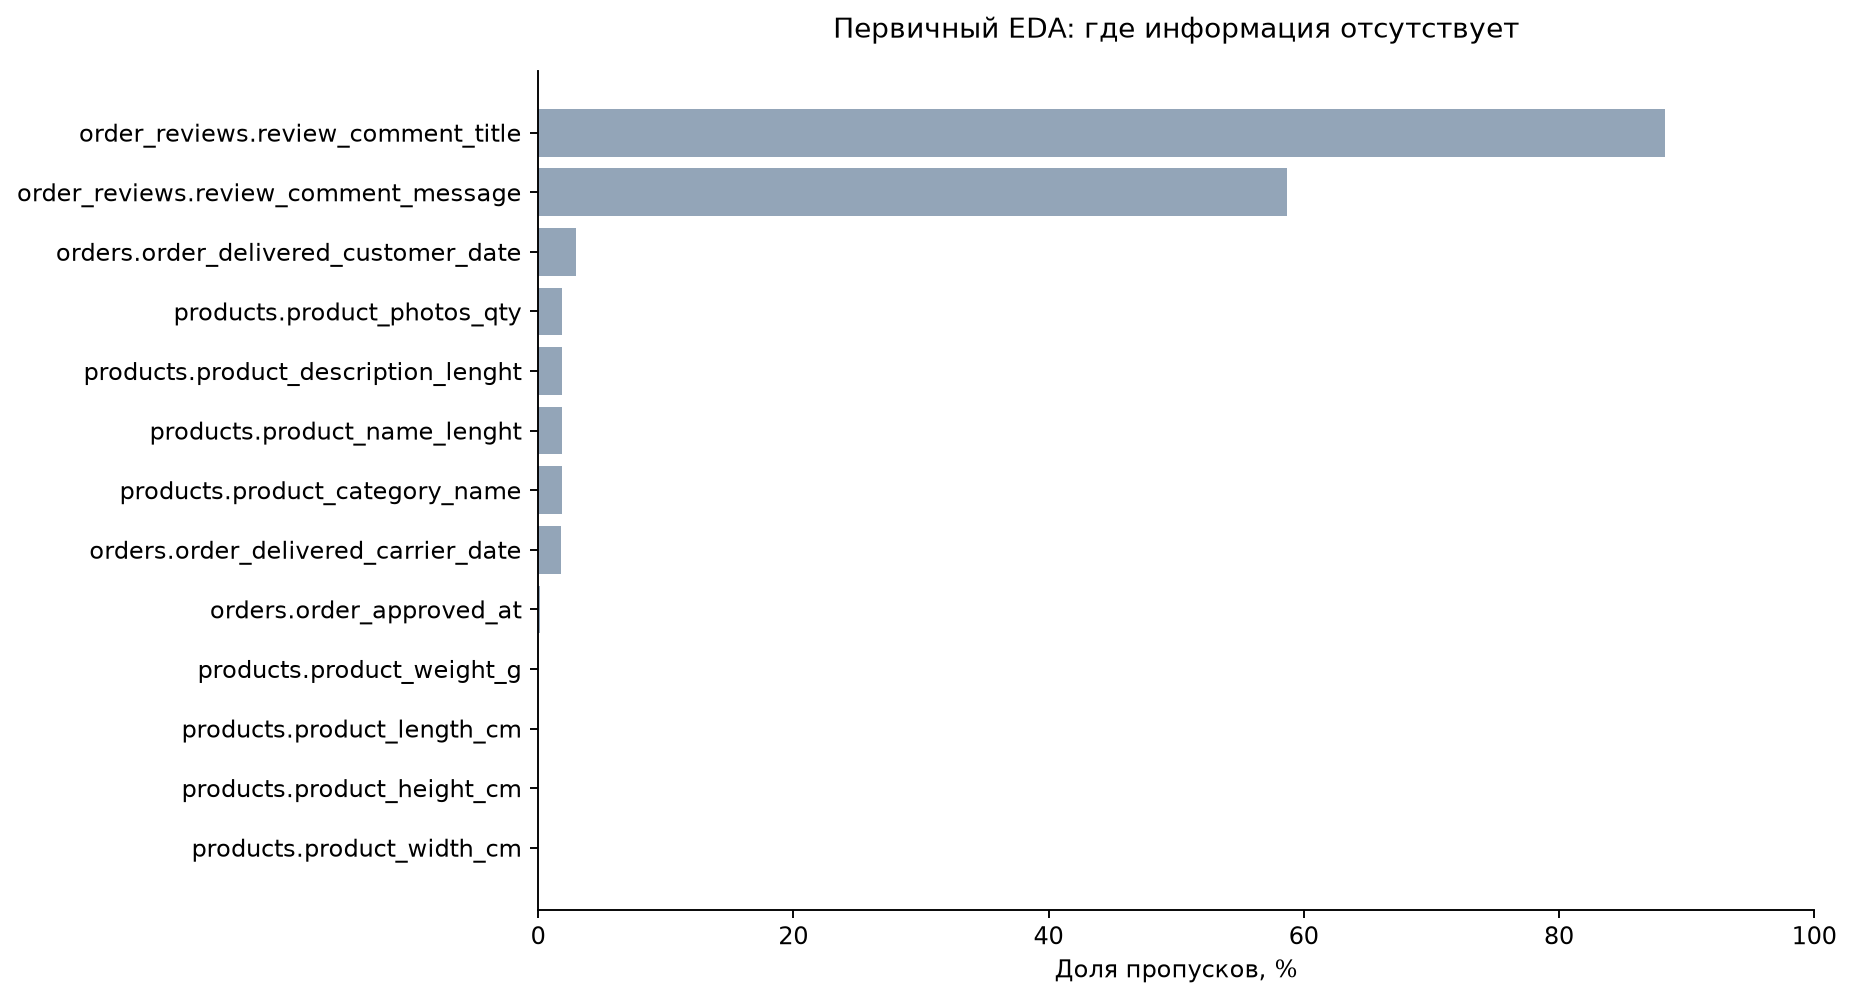

**Правило:** исходные пропуски сохраняются. Заполненная техническая категория unknown не означает, что настоящая категория восстановлена.

,status,orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [3]:
missing=pd.DataFrame([{'table':name,'column':c,'missing':int(df[c].isna().sum()),
                       'missing_pct':100*df[c].isna().mean(),'distinct':df[c].nunique(dropna=True)}
                      for name,df in raw.items() for c in df.columns])
display(missing[missing.missing>0].sort_values('missing_pct',ascending=False))
save_table(missing,'02_raw_missingness')
fig,ax=plt.subplots(figsize=(10,5))
s=schema.sort_values('rows')
ax.barh(s.table,s.rows,color=BLUE)
for y,value in enumerate(s.rows): ax.text(value+1000,y,f'{value:,}'.replace(',',' '),va='center')
ax.set_xlim(0,s.rows.max()*1.21);ax.set_xlabel('Количество исходных строк');ax.set_title('Восемь таблиц: разные объекты и разные уровни строки')
savefig(fig,'01_source_rows','**Вывод:** 99 441 заказ не равен 112 650 позициям. Это ожидаемая разница зерна, а не дубли заказов.')
top=missing[missing.missing>0].nlargest(14,'missing_pct').sort_values('missing_pct')
fig,ax=plt.subplots(figsize=(11,6))
ax.barh(top.table+'.'+top.column,top.missing_pct,color=GRAY)
ax.set_xlabel('Доля пропусков, %');ax.set_xlim(0,100);ax.set_title('Первичный EDA: где информация отсутствует')
savefig(fig,'02_missingness','**Правило:** исходные пропуски сохраняются. Заполненная техническая категория unknown не означает, что настоящая категория восстановлена.')
statuses=raw['orders'].order_status.value_counts().rename_axis('status').reset_index(name='orders')
display(statuses);save_table(statuses,'03_order_statuses')

## 4. Проверка ссылок и исходных особенностей
Существование родителя не гарантирует наличие дочерних записей.
Например, все позиции могут ссылаться на существующие заказы, но часть заказов не иметь позиций.

In [4]:
LINKS=[('orders','customer_id','customers','customer_id'),
       ('order_items','order_id','orders','order_id'),('order_items','product_id','products','product_id'),
       ('order_items','seller_id','sellers','seller_id'),('order_payments','order_id','orders','order_id'),
       ('order_reviews','order_id','orders','order_id')]
fk=[]
for child,col,parent,pk in LINKS:
    orphan=~raw[child][col].isin(raw[parent][pk])
    fk.append({'link':f'{child}.{col} -> {parent}.{pk}','orphan_rows':int(orphan.sum())})
fk=pd.DataFrame(fk);display(fk);save_table(fk,'04_raw_references')
assert fk.orphan_rows.sum()==0
no_items=~raw['orders'].order_id.isin(raw['order_items'].order_id)
no_payments=~raw['orders'].order_id.isin(raw['order_payments'].order_id)
multi_reviews=raw['order_reviews'].groupby('order_id').size().gt(1).sum()
print('Без позиций:',int(no_items.sum()),'; без оплаты:',int(no_payments.sum()),'; несколько отзывов:',int(multi_reviews))
display(raw['orders'].loc[no_items,'order_status'].value_counts().rename_axis('status').reset_index(name='orders_without_items'))
assert int(no_items.sum())==775 and int(no_payments.sum())==1 and int(multi_reviews)==547

,link,orphan_rows
0,orders.customer_id -> customers.customer_id,0
1,order_items.order_id -> orders.order_id,0
2,order_items.product_id -> products.product_id,0
3,order_items.seller_id -> sellers.seller_id,0
4,order_payments.order_id -> orders.order_id,0
5,order_reviews.order_id -> orders.order_id,0


Без позиций: 775 ; без оплаты: 1 ; несколько отзывов: 547


,status,orders_without_items
0,unavailable,603
1,canceled,164
2,created,5
3,invoiced,2
4,shipped,1


## 5. Договор обработки

1. Не удалять заказы без позиций/оплат и не фильтровать core только до delivered.
2. Не удалять отзывы через DISTINCT по review_id.
3. Даты приводить с учётом ошибок разбора; неизвестную дату не подменять обещанной.
4. Деньги перевести точно в целые сотые; оригинальные значения оставить в raw.
5. Пустую категорию выделить в `__unknown__`; непереведённую категорию сохранить отдельно.
6. Нормализованные города/штаты хранить дополнительными колонками, не переписывая исходные поля.
7. Соединять независимые факты только после агрегации до одинакового зерна.

Ключевые ошибки парсинга останавливают данный эксперимент. Аномалии бизнес-согласованности сохраняются с флагами.

In [5]:
typed={name:df.copy(deep=True) for name,df in raw.items()}
parse_log=[]
DATES={
 'orders':['order_purchase_timestamp','order_approved_at','order_delivered_carrier_date',
           'order_delivered_customer_date','order_estimated_delivery_date'],
 'order_items':['shipping_limit_date'],
 'order_reviews':['review_creation_date','review_answer_timestamp']}
NUMBERS={'order_items':['order_item_id'],'order_payments':['payment_sequential','payment_installments'],
 'order_reviews':['review_score'],'products':['product_name_lenght','product_description_lenght','product_photos_qty',
 'product_weight_g','product_length_cm','product_height_cm','product_width_cm']}
for table,cols in DATES.items():
    for col in cols:
        original=typed[table][col]
        parsed=pd.to_datetime(original,format='%Y-%m-%d %H:%M:%S',errors='coerce')
        errors=int((original.notna() & parsed.isna()).sum())
        parse_log.append({'table':table,'column':col,'target':'datetime64[ns]','errors':errors})
        typed[table][col]=parsed
for table,cols in NUMBERS.items():
    for col in cols:
        original=typed[table][col]
        parsed=pd.to_numeric(original,errors='coerce').astype('Int64')
        parse_log.append({'table':table,'column':col,'target':'Int64','errors':int((original.notna() & parsed.isna()).sum())})
        typed[table][col]=parsed
def cents(value):
    if pd.isna(value): return pd.NA
    value=Decimal(str(value).strip())*100
    if value!=value.to_integral_value(): raise ValueError('Деньги имеют больше двух десятичных знаков')
    return int(value)
for table,cols in {'order_items':['price','freight_value'],'order_payments':['payment_value']}.items():
    for col in cols:
        typed[table][col+'_cents']=typed[table][col].map(cents).astype('Int64')
        parse_log.append({'table':table,'column':col,'target':col+'_cents / Int64','errors':0})
for table in ['customers','sellers']:
    prefix='customer' if table=='customers' else 'seller'
    typed[table][prefix+'_city_normalized']=typed[table][prefix+'_city'].str.strip().str.lower()
    typed[table][prefix+'_state_normalized']=typed[table][prefix+'_state'].str.strip().str.upper()
parse_log=pd.DataFrame(parse_log);display(parse_log);save_table(parse_log,'05_parse_audit')
assert parse_log.errors.sum()==0
required={'orders':['order_status','order_purchase_timestamp'],
          'customers':['customer_unique_id'],
          'order_items':['price_cents','freight_value_cents','order_item_id'],
          'order_payments':['payment_value_cents','payment_sequential'],
          'order_reviews':['review_score']}
for table,columns in required.items():
    assert typed[table][columns].notna().all().all(), f'Пустое обязательное значение: {table}'
# Nullable boolean.all() по умолчанию пропускает NA: непустота проверяется отдельно.
assert typed['order_reviews'].review_score.between(1,5).all()
assert typed['order_items'].price_cents.ge(0).all() and typed['order_items'].freight_value_cents.ge(0).all()
assert typed['order_payments'].payment_value_cents.ge(0).all()
assert typed['order_items'].order_item_id.gt(0).all()
assert typed['order_payments'].payment_sequential.gt(0).all()
print('Оплата installments=0:',int(typed['order_payments'].payment_installments.eq(0).sum()),'— сохранена, не заменена догадкой')

,table,column,target,errors
0,orders,order_purchase_timestamp,datetime64[ns],0
1,orders,order_approved_at,datetime64[ns],0
2,orders,order_delivered_carrier_date,datetime64[ns],0
3,orders,order_delivered_customer_date,datetime64[ns],0
4,orders,order_estimated_delivery_date,datetime64[ns],0
5,order_items,shipping_limit_date,datetime64[ns],0
6,order_reviews,review_creation_date,datetime64[ns],0
7,order_reviews,review_answer_timestamp,datetime64[ns],0
8,order_items,order_item_id,Int64,0
9,order_payments,payment_sequential,Int64,0


Оплата installments=0: 2 — сохранена, не заменена догадкой


## 6. Категории: неизвестная ≠ непереведённая
Справочник строится из исходных названий товаров и переводов. Английская подпись необязательна.
Не используем INNER JOIN с неполным переводом как фильтр допустимых товаров.

In [6]:
products=typed['products'];translations=typed['product_category_translation']
known=pd.concat([products.product_category_name,translations.product_category_name]).dropna().str.strip()
known=known[known.ne('')].drop_duplicates().sort_values()
assert '__unknown__' not in set(known)
categories=pd.DataFrame({'category_key':known}).reset_index(drop=True)
categories=categories.merge(translations.rename(columns={'product_category_name':'category_key'}),
                            on='category_key',how='left',validate='one_to_one')
categories['is_unknown']=False
categories=pd.concat([categories,pd.DataFrame({'category_key':['__unknown__'],
                         'product_category_name_english':['Неизвестная категория'],'is_unknown':[True]})],ignore_index=True)
categories['label']=categories.product_category_name_english.fillna(categories.category_key)
products['category_key']=products.product_category_name.str.strip().replace('',pd.NA).fillna('__unknown__')
products['is_missing_category']=products.product_category_name.isna() | products.product_category_name.str.strip().eq('').fillna(False)
untranslated=categories[categories.product_category_name_english.isna()]
display(untranslated[['category_key','label']])
print('Категорий:',len(categories),'; товаров без категории:',int(products.is_missing_category.sum()))
assert len(categories)==74 and int(products.is_missing_category.sum())==610 and len(untranslated)==2

,category_key,label
60,pc_gamer,pc_gamer
65,portateis_cozinha_e_preparadores_de_alimentos,portateis_cozinha_e_preparadores_de_alimentos


Категорий: 74 ; товаров без категории: 610


## 7. Безопасное зерно заказа
Позиции, оплаты и отзывы сначала сворачиваются независимо.
`validate` проверяет ожидаемую кратность merge. В pandas NULL-ключи могут совпадать
между собой, поэтому непустота ключей была проверена **до** соединений.
Отсутствующая сумма остаётся NA; отсутствие состава не превращаем в настоящий нулевой чек.

In [7]:
items=typed['order_items'];payments=typed['order_payments'];reviews=typed['order_reviews']
item_agg=items.groupby('order_id',as_index=False).agg(
    line_count=('order_item_id','size'),goods_cents=('price_cents','sum'),
    freight_cents=('freight_value_cents','sum'),seller_count=('seller_id','nunique'))
item_agg['order_cents']=item_agg.goods_cents+item_agg.freight_cents
payment_agg=payments.groupby('order_id',as_index=False).agg(payment_count=('payment_sequential','size'),payment_cents=('payment_value_cents','sum'))
reviews['has_text']=reviews.review_comment_message.str.strip().notna() & reviews.review_comment_message.str.strip().ne('').fillna(False)
review_agg=reviews.groupby('order_id',as_index=False).agg(review_count=('review_id','size'),review_score_mean=('review_score','mean'),text_count=('has_text','sum'))
summary=typed['orders'].merge(typed['customers'][['customer_id','customer_unique_id','customer_state_normalized']],
                             on='customer_id',how='left',validate='many_to_one')
for block in [item_agg,payment_agg,review_agg]:
    summary=summary.merge(block,on='order_id',how='left',validate='one_to_one')
summary['has_items']=summary.line_count.notna();summary['has_payments']=summary.payment_count.notna()
for col in ['line_count','seller_count','payment_count','review_count','text_count']:
    summary[col]=summary[col].fillna(0).astype('Int64')
both=summary.has_items & summary.has_payments
summary['payment_delta_cents']=(summary.payment_cents-summary.order_cents).where(both)
summary['reconciliation']=np.select([
    ~summary.has_items & ~summary.has_payments,~summary.has_items,~summary.has_payments,
    summary.payment_delta_cents.eq(0).fillna(False).to_numpy(dtype=bool)],
    ['Нет обеих сторон','Нет позиций','Нет оплаты','Совпадает'],default='Расхождение')
assert len(summary)==len(raw['orders']) and summary.order_id.is_unique
assert set(summary.order_id)==set(raw['orders'].order_id)
assert int(summary.line_count.sum())==len(items)
assert int(summary.payment_count.sum())==len(payments)
assert int(summary.review_count.sum())==len(reviews)
assert int(summary.goods_cents.sum())==int(items.price_cents.sum())
assert int(summary.freight_cents.sum())==int(items.freight_value_cents.sum())
assert int(summary.payment_cents.sum())==int(payments.payment_value_cents.sum())
print('Итоговая витрина:',summary.shape,'; одна строка на заказ:',summary.order_id.is_unique)
display(summary[['order_id','has_items','has_payments','goods_cents','freight_cents','payment_cents','reconciliation']].head())

Итоговая витрина: (99441, 24) ; одна строка на заказ: True


,order_id,has_items,has_payments,goods_cents,freight_cents,payment_cents,reconciliation
0,e481f51cbdc54678b7cc49136f2d6af7,True,True,2999,872,3871,Совпадает
1,53cdb2fc8bc7dce0b6741e2150273451,True,True,11870,2276,14146,Совпадает
2,47770eb9100c2d0c44946d9cf07ec65d,True,True,15990,1922,17912,Совпадает
3,949d5b44dbf5de918fe9c16f97b45f8a,True,True,4500,2720,7220,Совпадает
4,ad21c59c0840e6cb83a9ceb5573f8159,True,True,1990,872,2862,Совпадает


## 8. Повторный EDA и проверка сохранения
Успех предобработки — не «везде ноль пропусков». Здесь успех: типы разобраны,
связи и суммы проверены, строки сохранены, неизвестность показана явно.

In [8]:
comparison=schema[['table','rows']].rename(columns={'rows':'rows_before'})
comparison['rows_after']=[len(typed[name]) for name in comparison.table]
comparison['rows_removed']=comparison.rows_before-comparison.rows_after
comparison['parse_errors']=[int(parse_log.loc[parse_log.table.eq(name),'errors'].sum()) for name in comparison.table]
display(comparison);save_table(comparison,'06_before_after')
assert comparison.rows_removed.eq(0).all()
for name,keys in KEYS.items():
    # Проверяем состав ключей, а не только одинаковое число строк.
    before=raw[name][keys].astype('string').reset_index(drop=True)
    after=typed[name][keys].astype('string').reset_index(drop=True)
    pd.testing.assert_frame_equal(before,after)
recon=summary.reconciliation.value_counts().rename_axis('status').reset_index(name='orders')
display(recon);save_table(recon,'07_reconciliation')
mismatch=both & summary.payment_delta_cents.ne(0).fillna(False)
assert int(mismatch.sum())==639
assert int((both & summary.payment_delta_cents.abs().gt(1).fillna(False)).sum())==366
print('8 delivered без даты вручения:',int((summary.order_status.eq('delivered') & summary.order_delivered_customer_date.isna()).sum()))

,table,rows_before,rows_after,rows_removed,parse_errors
0,orders,99441,99441,0,0
1,order_items,112650,112650,0,0
2,order_payments,103886,103886,0,0
3,order_reviews,99224,99224,0,0
4,products,32951,32951,0,0
5,sellers,3095,3095,0,0
6,customers,99441,99441,0,0
7,product_category_translation,71,71,0,0


,status,orders
0,Совпадает,98026
1,Нет позиций,775
2,Расхождение,639
3,Нет оплаты,1


8 delivered без даты вручения: 8


## 9. Аналитическая совокупность и пять контролей
Фильтр delivered используется для продаж и среднего чека. Повторность — среди всех оформленных заказов.
Данные ноутбука служат исследованием/прототипом; финальная сдача должна повторить определения SQL-запросами из модели.

In [9]:
delivered=summary[summary.order_status.eq('delivered')].copy()
sales=items.merge(typed['orders'][['order_id','order_status','order_purchase_timestamp']],on='order_id',how='left',validate='many_to_one')
sales=sales.merge(products[['product_id','category_key']],on='product_id',how='left',validate='many_to_one')
sales=sales.merge(categories[['category_key','label']],on='category_key',how='left',validate='many_to_one')
assert len(sales)==len(items)
delivered_sales=sales[sales.order_status.eq('delivered')].copy()
window=delivered[delivered.order_purchase_timestamp.ge('2016-09-01') & delivered.order_purchase_timestamp.lt('2018-09-01')].copy()
window['month']=window.order_purchase_timestamp.dt.to_period('M').dt.to_timestamp()
monthly=window.groupby('month').agg(order_count=('order_id','size'),revenue_cents=('goods_cents','sum'))
monthly=monthly.reindex(pd.date_range('2016-09-01','2018-08-01',freq='MS'),fill_value=0).rename_axis('month').reset_index()
seller=delivered_sales.groupby('seller_id',as_index=False).agg(revenue_cents=('price_cents','sum'),orders=('order_id','nunique'),units=('order_item_id','size'))
seller=seller.merge(typed['sellers'][['seller_id','seller_city','seller_state']],on='seller_id',how='left',validate='one_to_one').sort_values(['revenue_cents','seller_id'],ascending=[False,True])
by_category=delivered_sales.groupby(['category_key','label'],as_index=False).agg(revenue_cents=('price_cents','sum')).sort_values('revenue_cents',ascending=False)
by_category['share_pct']=by_category.revenue_cents.astype(float)/float(by_category.revenue_cents.sum())*100
person_counts=summary.groupby('customer_unique_id').order_id.nunique()
people=len(person_counts);repeat=int(person_counts.ge(2).sum())
revenue=int(delivered.goods_cents.sum())
assert delivered.has_items.all()
aov=(amount(delivered.order_cents.sum())/len(delivered)).quantize(Decimal('.01'),rounding=ROUND_HALF_UP)
checks=pd.DataFrame([
 {'check':'Месяцев','expected':'24','actual':str(len(monthly))},
 {'check':'Товарная выручка','expected':'13221498.11','actual':str(amount(revenue))},
 {'check':'Первый продавец','expected':'226987.93','actual':str(amount(seller.iloc[0].revenue_cents))},
 {'check':'Средний чек','expected':'159.88','actual':str(aov)},
 {'check':'Покупателей','expected':'96096','actual':str(people)},
 {'check':'Повторных','expected':'2997','actual':str(repeat)},
 {'check':'Категорий','expected':'74','actual':str(len(by_category))},
 {'check':'Первая категория','expected':'1233131.72','actual':str(amount(by_category.iloc[0].revenue_cents))}])
checks['passed']=checks.expected.eq(checks.actual)
display(checks);save_table(checks,'08_business_controls')
assert checks.passed.all()
assert int(monthly.revenue_cents.sum())==revenue==int(by_category.revenue_cents.sum())
assert int(seller.revenue_cents.sum())==revenue
assert sales.category_key.notna().all() and sales.label.notna().all()
assert len(monthly[monthly.revenue_cents.eq(0)])==1
assert str(monthly.loc[monthly.revenue_cents.eq(0),'month'].iloc[0].date())=='2016-11-01'
print('Повторных:',round(repeat/people*100,2),'%; средних строк и единиц:',delivered.line_count.mean())
for df,name in [(monthly,'09_monthly'),(seller.head(10),'10_top_sellers'),(by_category,'11_categories')]:save_table(df,name)

,check,expected,actual,passed
0,Месяцев,24,24,True
1,Товарная выручка,13221498.11,13221498.11,True
2,Первый продавец,226987.93,226987.93,True
3,Средний чек,159.88,159.88,True
4,Покупателей,96096,96096,True
5,Повторных,2997,2997,True
6,Категорий,74,74,True
7,Первая категория,1233131.72,1233131.72,True


Повторных: 3.12 %; средних строк и единиц: 1.1421982213561641


## 10. Визуализация бизнес-показателей
На графиках денежные значения могут преобразовываться в float только для отображения.
Все точные проверки выше выполнялись в целых сотых.

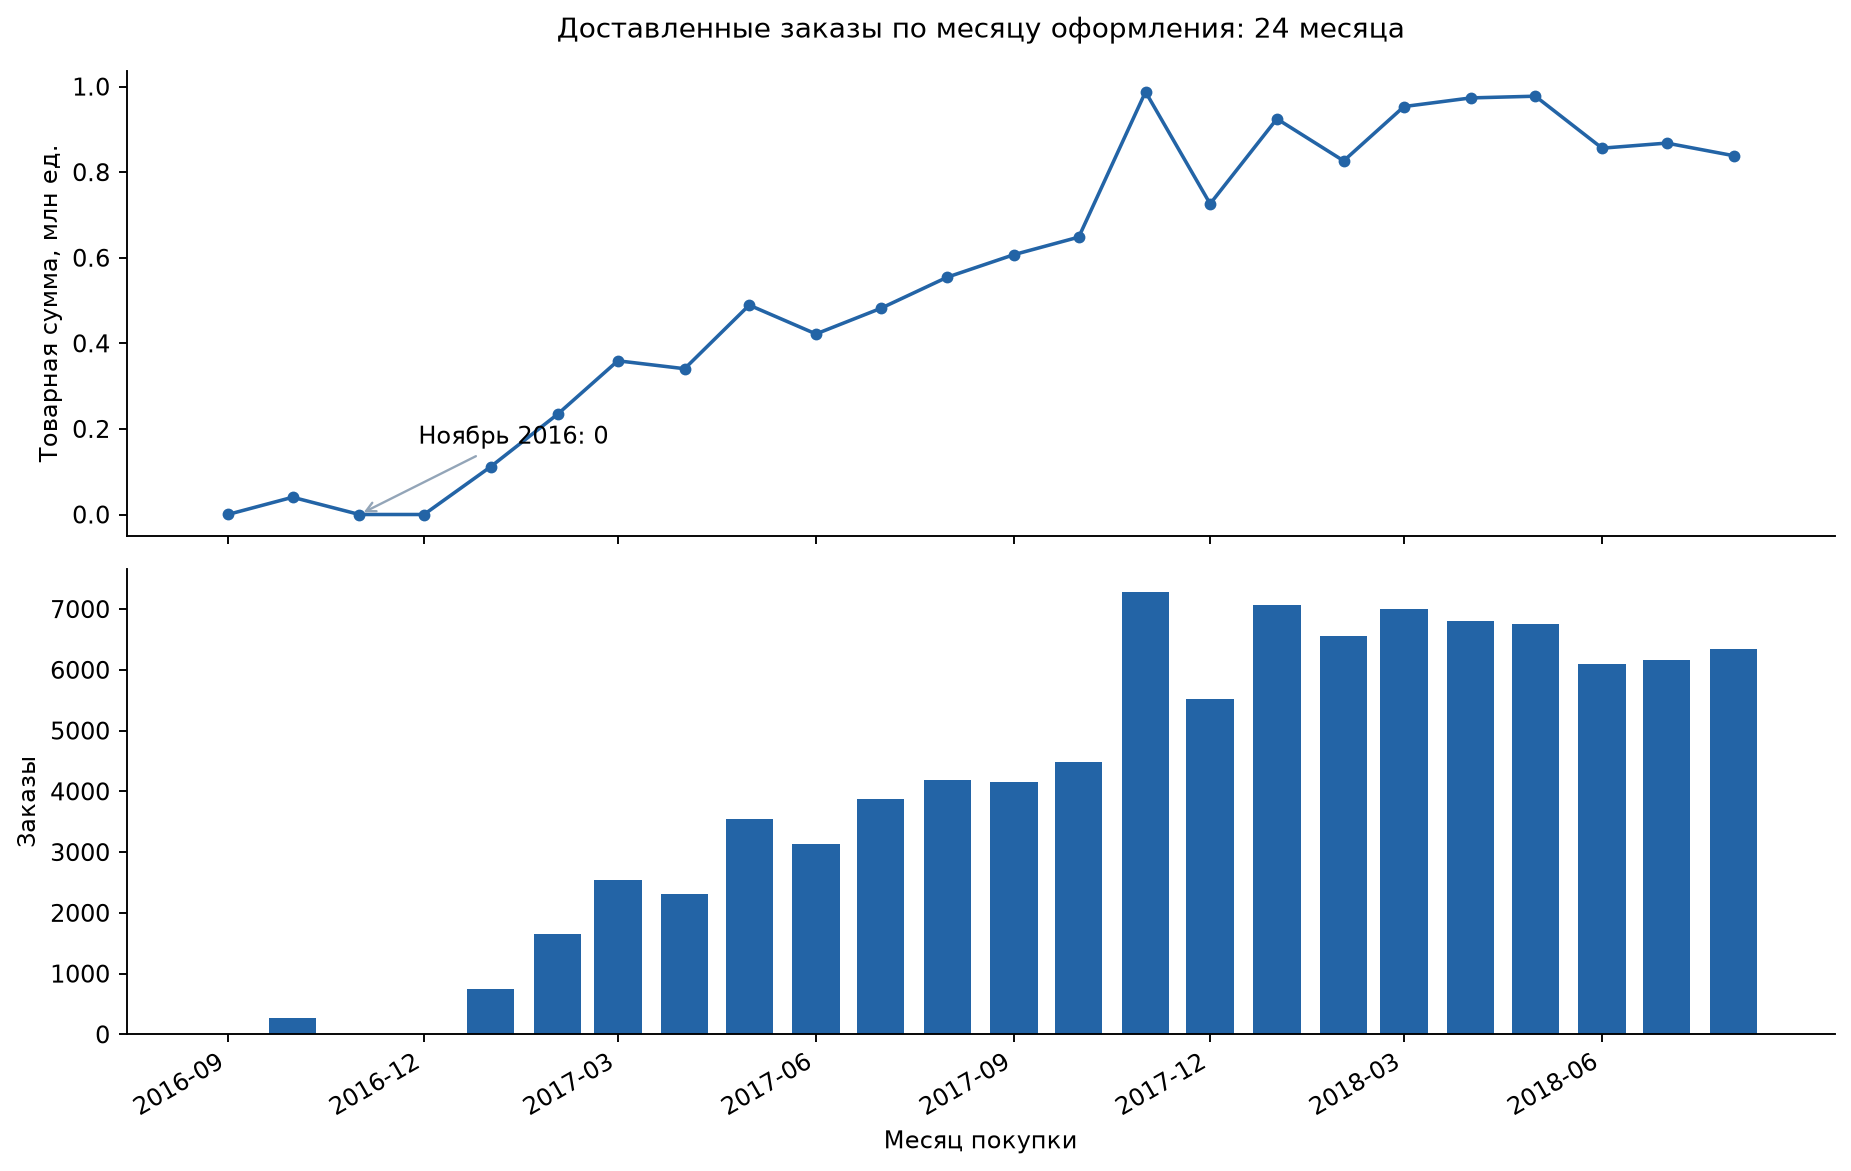

**Контроль:** календарная сетка сохраняет ноябрь 2016 с нулём. Ряд относится к delivered по итоговому снимку, а не к состоянию отчёта на конец каждого месяца.

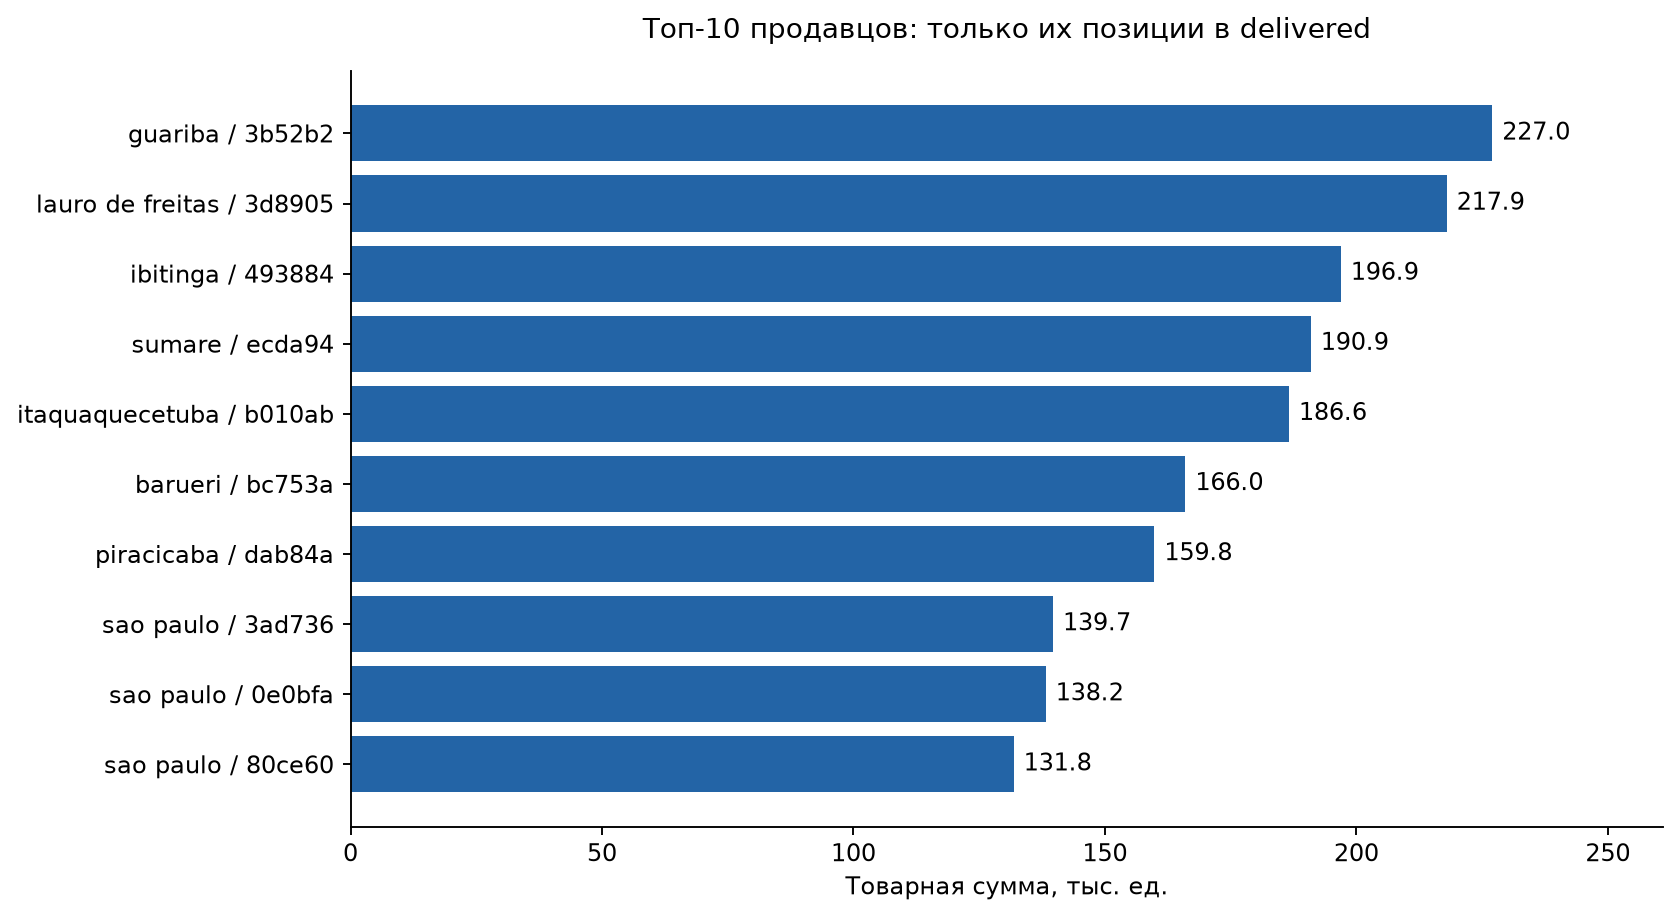

**Единица расчёта:** позиция продавца, а не весь чек заказа. Полные ID и число заказов/единиц находятся в CSV-таблице.

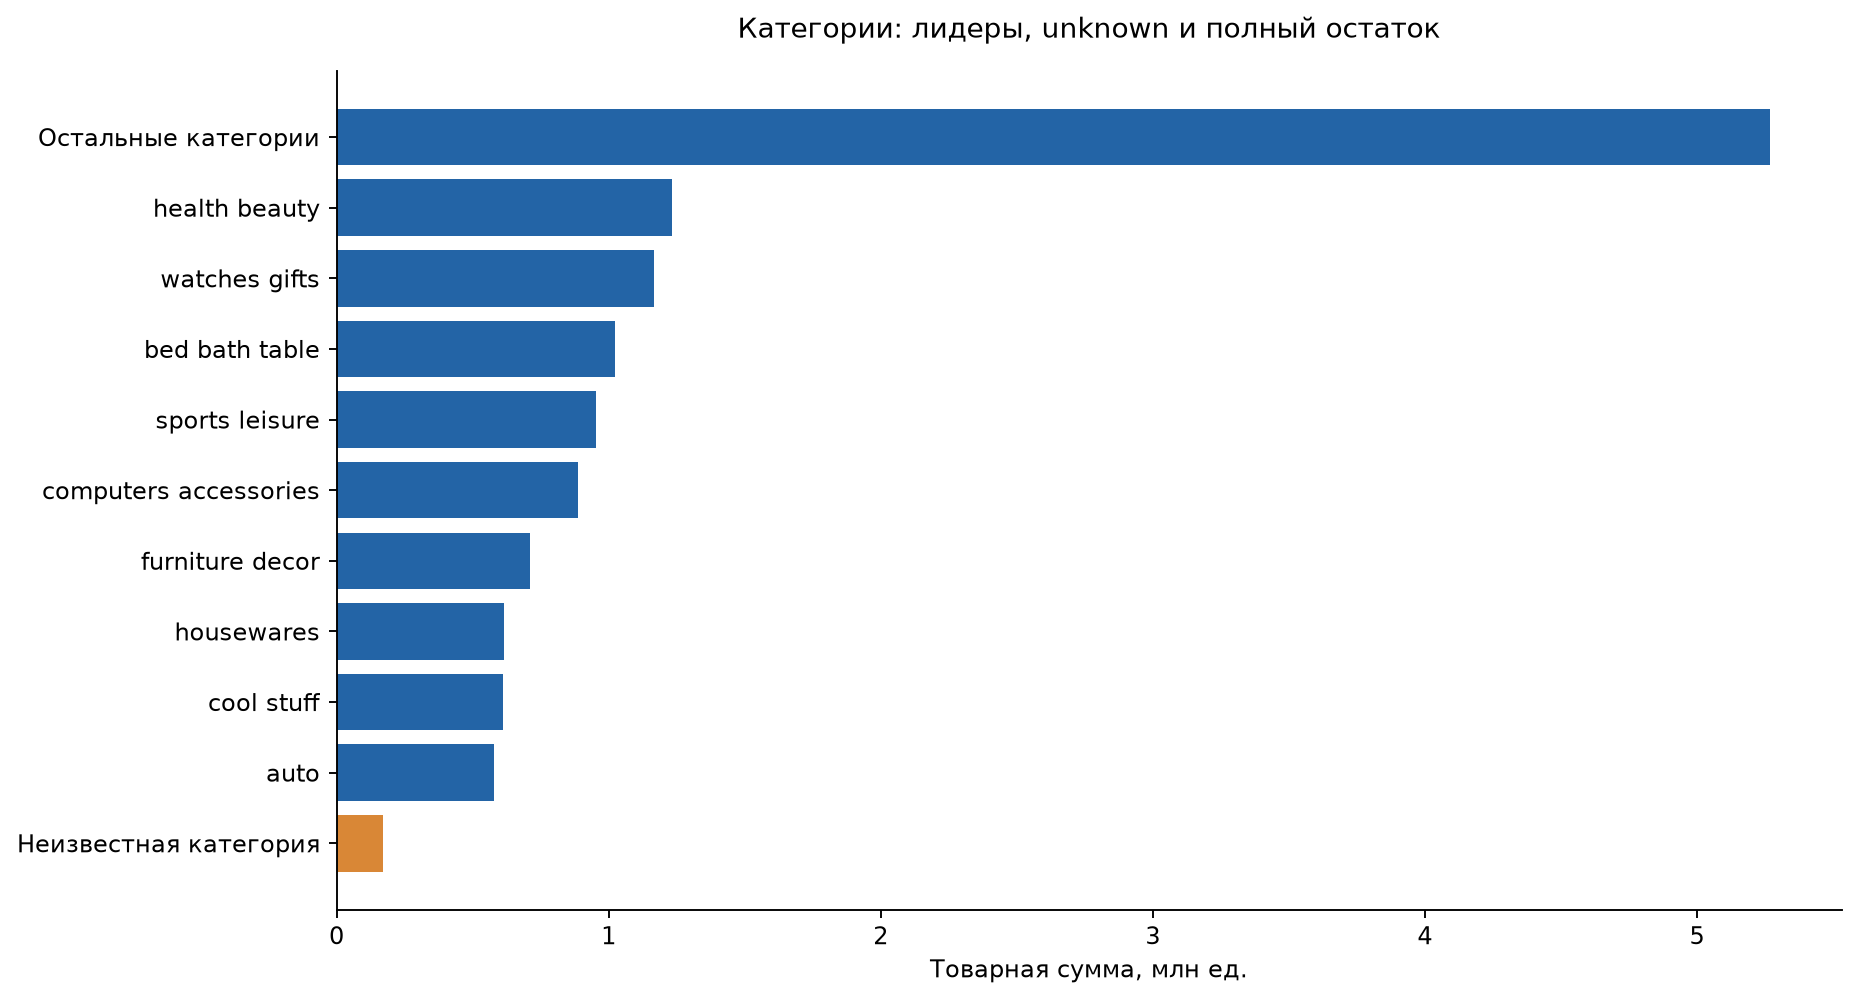

**Важно:** unknown не скрыт, остальные категории объединены только на графике. Сумма всех показанных групп равна общей выручке.

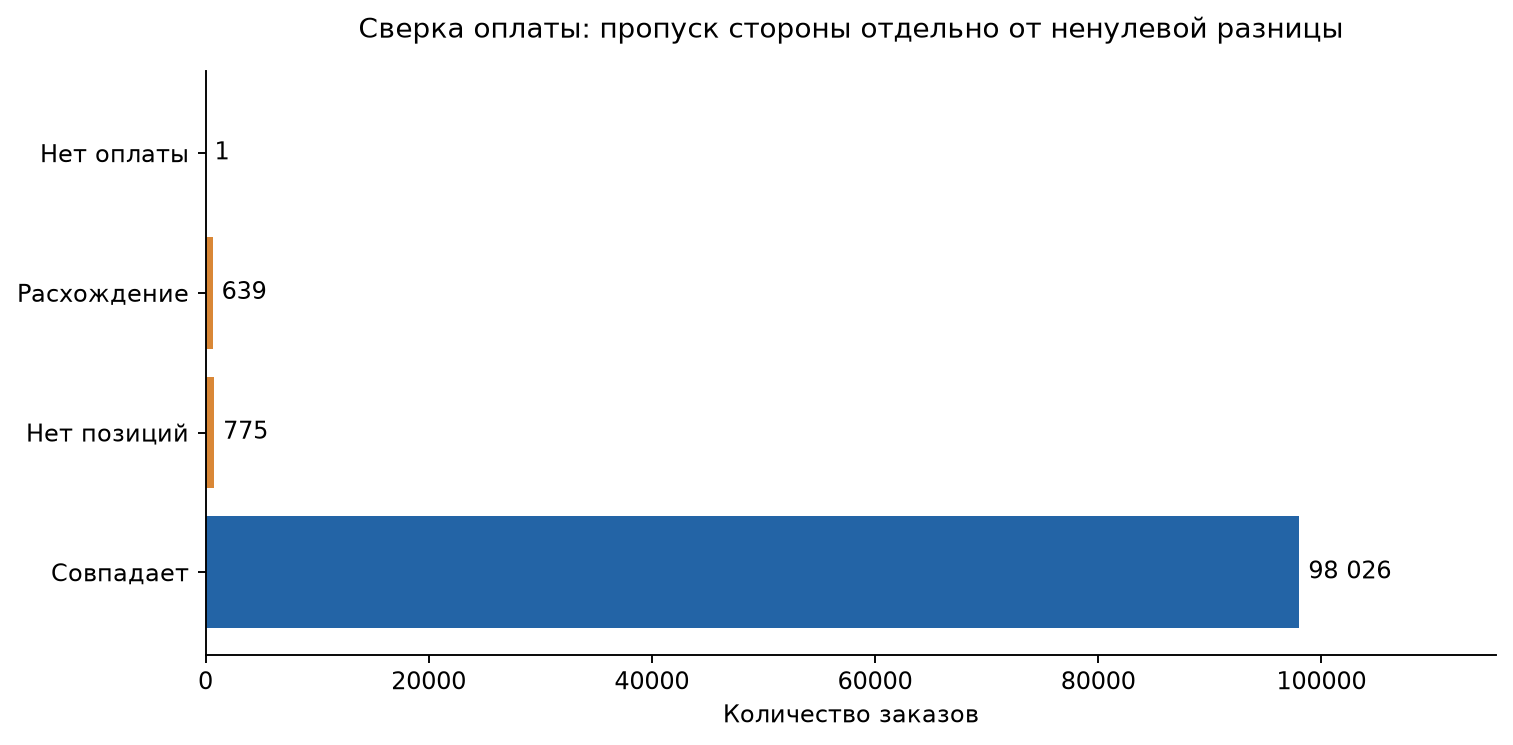

**Не интерпретировать как доказанную недоплату:** причины денежных расхождений по этому набору не установлены.

In [10]:
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
axes[0].plot(monthly.month,monthly.revenue_cents.astype(float)/100/1e6,color=BLUE,marker='o',markersize=4)
axes[0].set_ylabel('Товарная сумма, млн ед.');axes[0].set_title('Доставленные заказы по месяцу оформления: 24 месяца')
axes[0].annotate('Ноябрь 2016: 0',xy=(pd.Timestamp('2016-11-01'),0),xytext=(25,30),textcoords='offset points',arrowprops={'arrowstyle':'->','color':GRAY})
axes[1].bar(monthly.month,monthly.order_count,color=BLUE,width=22)
axes[1].set_ylabel('Заказы');axes[1].set_xlabel('Месяц покупки')
axes[1].set_xticks(monthly.month.iloc[::3]);axes[1].set_xticklabels(monthly.month.iloc[::3].dt.strftime('%Y-%m'),rotation=30,ha='right')
savefig(fig,'03_monthly_sales','**Контроль:** календарная сетка сохраняет ноябрь 2016 с нулём. Ряд относится к delivered по итоговому снимку, а не к состоянию отчёта на конец каждого месяца.')

top=seller.head(10).iloc[::-1]
fig,ax=plt.subplots(figsize=(10,5.5))
labels=top.seller_city+' / '+top.seller_id.str[-6:]
vals=top.revenue_cents.astype(float)/100/1000
ax.barh(labels,vals,color=BLUE)
for y,v in enumerate(vals):ax.text(v+2,y,f'{v:.1f}',va='center')
ax.set_xlim(0,vals.max()*1.15);ax.set_xlabel('Товарная сумма, тыс. ед.');ax.set_title('Топ-10 продавцов: только их позиции в delivered')
savefig(fig,'04_top_sellers','**Единица расчёта:** позиция продавца, а не весь чек заказа. Полные ID и число заказов/единиц находятся в CSV-таблице.')

subset=by_category.head(9).copy()
unknown=by_category[by_category.category_key.eq('__unknown__')]
if '__unknown__' not in set(subset.category_key):subset=pd.concat([subset,unknown])
rest=int(by_category.revenue_cents.sum()-subset.revenue_cents.sum())
plot=pd.concat([subset[['label','revenue_cents']],pd.DataFrame({'label':['Остальные категории'],'revenue_cents':[rest]})]).sort_values('revenue_cents')
fig,ax=plt.subplots(figsize=(11,6))
ax.barh(plot.label.str.replace('_',' ',regex=False),plot.revenue_cents.astype(float)/100/1e6,
        color=[ORANGE if x=='Неизвестная категория' else BLUE for x in plot.label])
ax.set_xlabel('Товарная сумма, млн ед.');ax.set_title('Категории: лидеры, unknown и полный остаток')
savefig(fig,'05_categories','**Важно:** unknown не скрыт, остальные категории объединены только на графике. Сумма всех показанных групп равна общей выручке.')

fig,ax=plt.subplots(figsize=(9,4.5))
ax.barh(recon.status,recon.orders,color=[BLUE if s=='Совпадает' else ORANGE for s in recon.status])
for y,n in enumerate(recon.orders):ax.text(n+800,y,f'{n:,}'.replace(',',' '),va='center')
ax.set_xlim(0,recon.orders.max()*1.18);ax.set_xlabel('Количество заказов');ax.set_title('Сверка оплаты: пропуск стороны отдельно от ненулевой разницы')
savefig(fig,'06_payment_reconciliation','**Не интерпретировать как доказанную недоплату:** причины денежных расхождений по этому набору не установлены.')

## 11. Повторный EDA доставки и отзывов
Срок доставки — разность фактического вручения и покупки. Опоздание здесь определяется
по календарным дням относительно обещанного дня. Оценка отзыва — 1–5, это не NPS.
Связь оценки с опозданием не доказывает причину и не позволяет назначить виновного продавца.

,valid_orders,delivered_orders,late_orders,late_percent,median_days,p90_days,max_days
0,96470,96478,6534,6.77309,10.217477,23.096377,209.628611


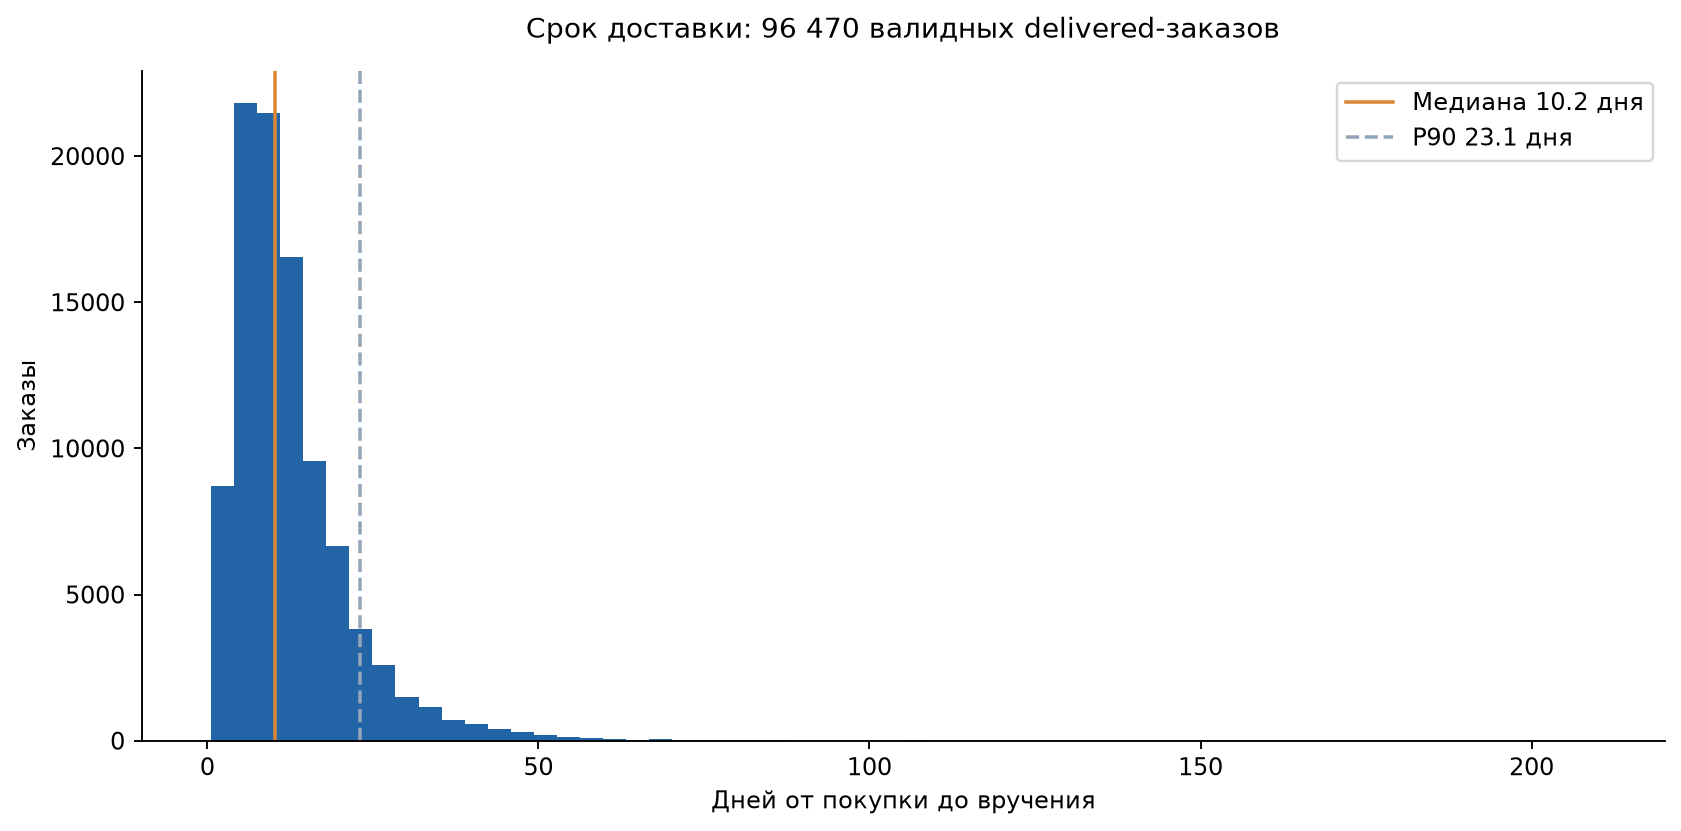

**Покрытие:** сохранены все валидные длительности, хвост не удалён. Восемь delivered без даты вручения не участвуют в длительности, но остаются в продажах по статусу.

,delay_group,orders,mean_score
0,В срок,89443,4.290589
1,1–3 дня,1852,3.291037
2,4–7 дней,1748,2.105549
3,Более 7 дней,2781,1.697591


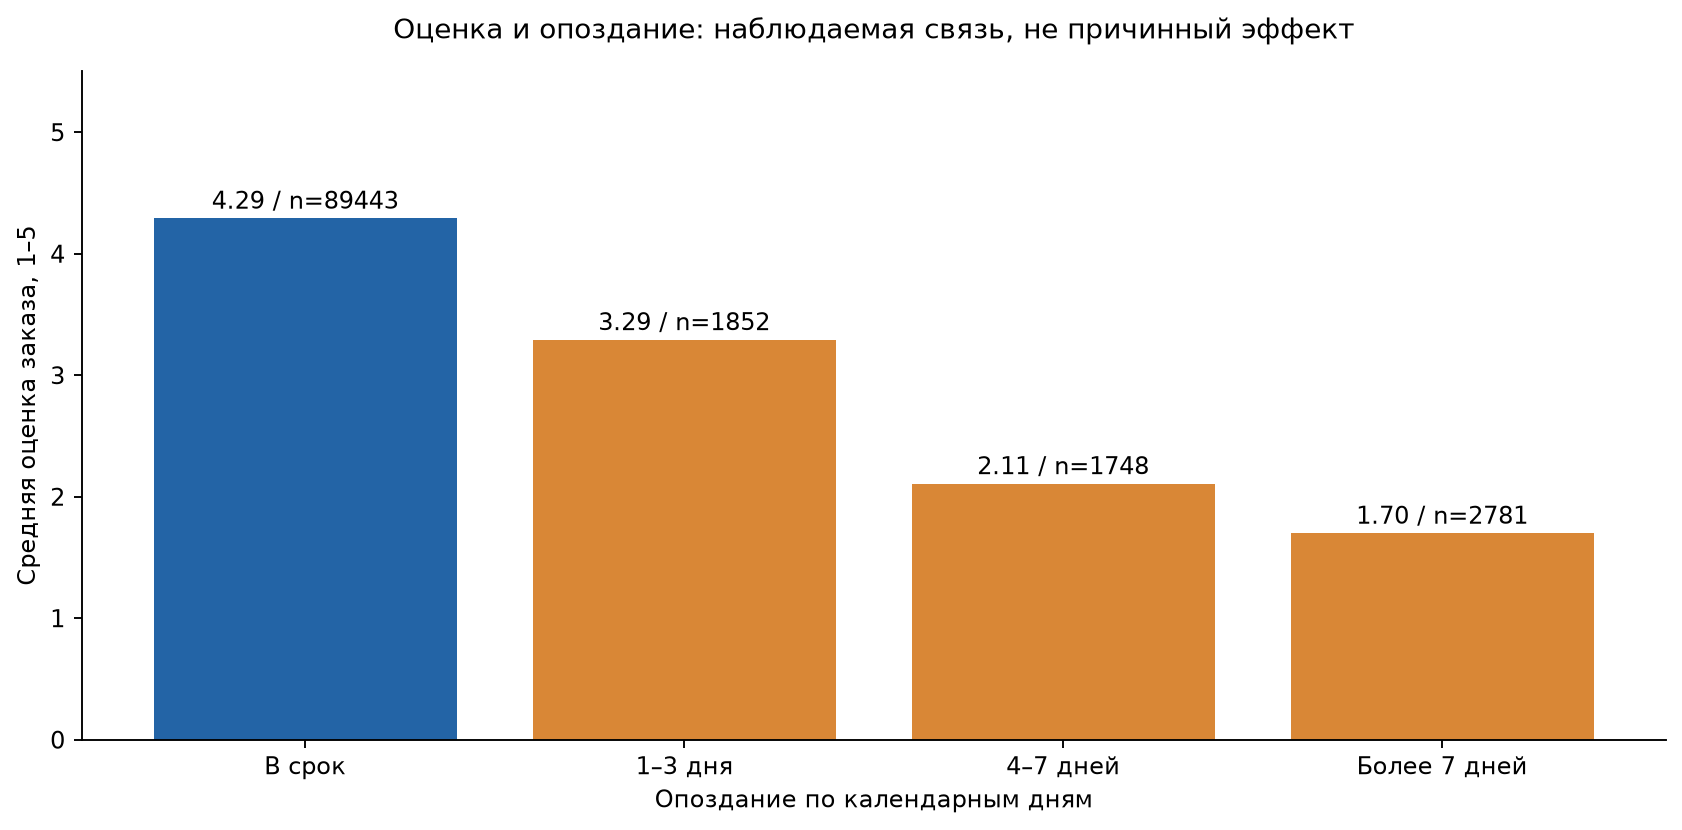

**Зерно:** сначала средняя оценка отзывов каждого заказа, затем среднее по заказам. Отсутствующие отзывы не считаются нулевой оценкой; результаты относятся к ответившим заказам с валидными датами.

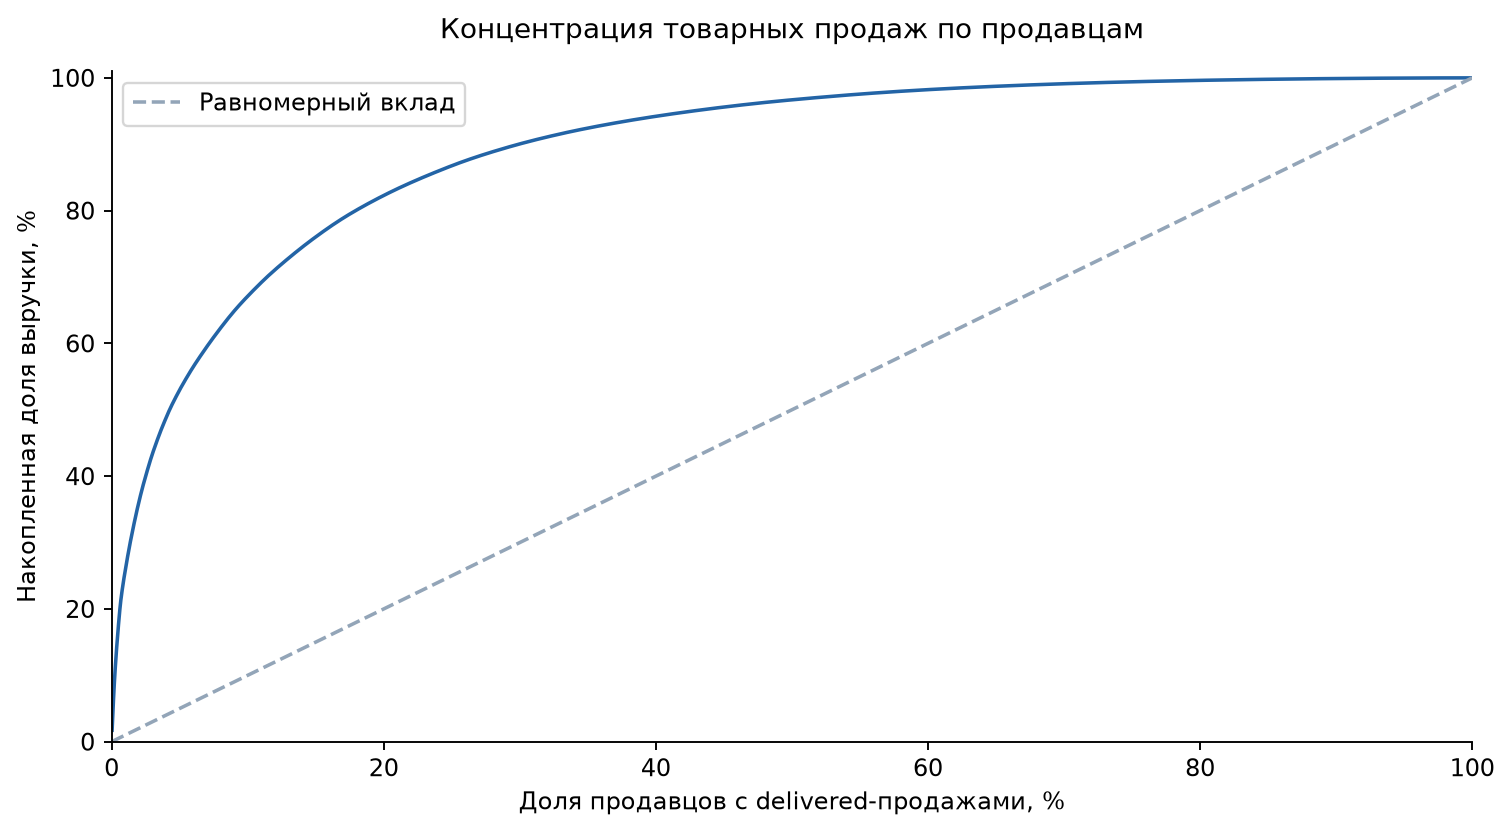

**Ограничение:** концентрация продаж описывает вклад, а не качество или вину продавца. Нужен отдельный контракт оценки надёжности.

In [11]:
summary['delivery_days']=(summary.order_delivered_customer_date-summary.order_purchase_timestamp).dt.total_seconds()/86400
summary['delay_calendar_days']=(summary.order_delivered_customer_date.dt.normalize()-summary.order_estimated_delivery_date.dt.normalize()).dt.days
valid=(summary.order_status.eq('delivered') & summary.order_delivered_customer_date.notna()
       & summary.order_estimated_delivery_date.notna() & summary.delivery_days.ge(0))
delivery=summary.loc[valid].copy()
late=delivery.delay_calendar_days.gt(0)
delivery_metrics={'valid_orders':len(delivery),'delivered_orders':len(delivered),
                  'late_orders':int(late.sum()),'late_percent':float(late.mean()*100),
                  'median_days':float(delivery.delivery_days.median()),
                  'p90_days':float(delivery.delivery_days.quantile(.9)),
                  'max_days':float(delivery.delivery_days.max())}
display(pd.DataFrame([delivery_metrics]));save_table(pd.DataFrame([delivery_metrics]),'12_delivery_metrics')
fig,ax=plt.subplots(figsize=(10,5))
ax.hist(delivery.delivery_days,bins=60,color=BLUE)
ax.axvline(delivery_metrics['median_days'],color=ORANGE,label=f"Медиана {delivery_metrics['median_days']:.1f} дня")
ax.axvline(delivery_metrics['p90_days'],color=GRAY,linestyle='--',label=f"P90 {delivery_metrics['p90_days']:.1f} дня")
ax.set_xlabel('Дней от покупки до вручения');ax.set_ylabel('Заказы');ax.set_title(f'Срок доставки: {len(delivery):,} валидных delivered-заказов'.replace(',',' '));ax.legend()
savefig(fig,'07_delivery_distribution','**Покрытие:** сохранены все валидные длительности, хвост не удалён. Восемь delivered без даты вручения не участвуют в длительности, но остаются в продажах по статусу.')

delivery['delay_group']=pd.cut(delivery.delay_calendar_days,bins=[-np.inf,0,3,7,np.inf],labels=['В срок','1–3 дня','4–7 дней','Более 7 дней'])
scores=delivery.dropna(subset=['review_score_mean']).groupby('delay_group',observed=False).agg(
    orders=('order_id','size'),mean_score=('review_score_mean','mean')).reset_index()
save_table(scores,'13_delivery_and_reviews');display(scores)
fig,ax=plt.subplots(figsize=(10,5))
ax.bar(scores.delay_group.astype(str),scores.mean_score,color=[BLUE,ORANGE,ORANGE,ORANGE])
for x,row in enumerate(scores.itertuples()):ax.text(x,row.mean_score+.08,f'{row.mean_score:.2f} / n={row.orders}',ha='center')
ax.set_ylim(0,5.5);ax.set_ylabel('Средняя оценка заказа, 1–5');ax.set_xlabel('Опоздание по календарным дням');ax.set_title('Оценка и опоздание: наблюдаемая связь, не причинный эффект')
savefig(fig,'08_delivery_and_reviews','**Зерно:** сначала средняя оценка отзывов каждого заказа, затем среднее по заказам. Отсутствующие отзывы не считаются нулевой оценкой; результаты относятся к ответившим заказам с валидными датами.')

ordered=seller.sort_values('revenue_cents',ascending=False).reset_index(drop=True)
x=np.arange(1,len(ordered)+1)/len(ordered)*100
y=ordered.revenue_cents.astype(float).cumsum()/float(ordered.revenue_cents.sum())*100
fig,ax=plt.subplots(figsize=(9,5))
ax.plot(x,y,color=BLUE);ax.plot([0,100],[0,100],color=GRAY,linestyle='--',label='Равномерный вклад')
ax.set_xlim(0,100);ax.set_ylim(0,101);ax.set_xlabel('Доля продавцов с delivered-продажами, %');ax.set_ylabel('Накопленная доля выручки, %');ax.set_title('Концентрация товарных продаж по продавцам');ax.legend()
savefig(fig,'09_seller_concentration','**Ограничение:** концентрация продаж описывает вклад, а не качество или вину продавца. Нужен отдельный контракт оценки надёжности.')

## 12. Что изменилось после обработки — и что не изменилось
Сравним исходные строки и типизированные копии. Бизнес-NULL сохраняются там,
где настоящего значения нет. Unknown — явная метка отсутствия, не восстановленная категория.

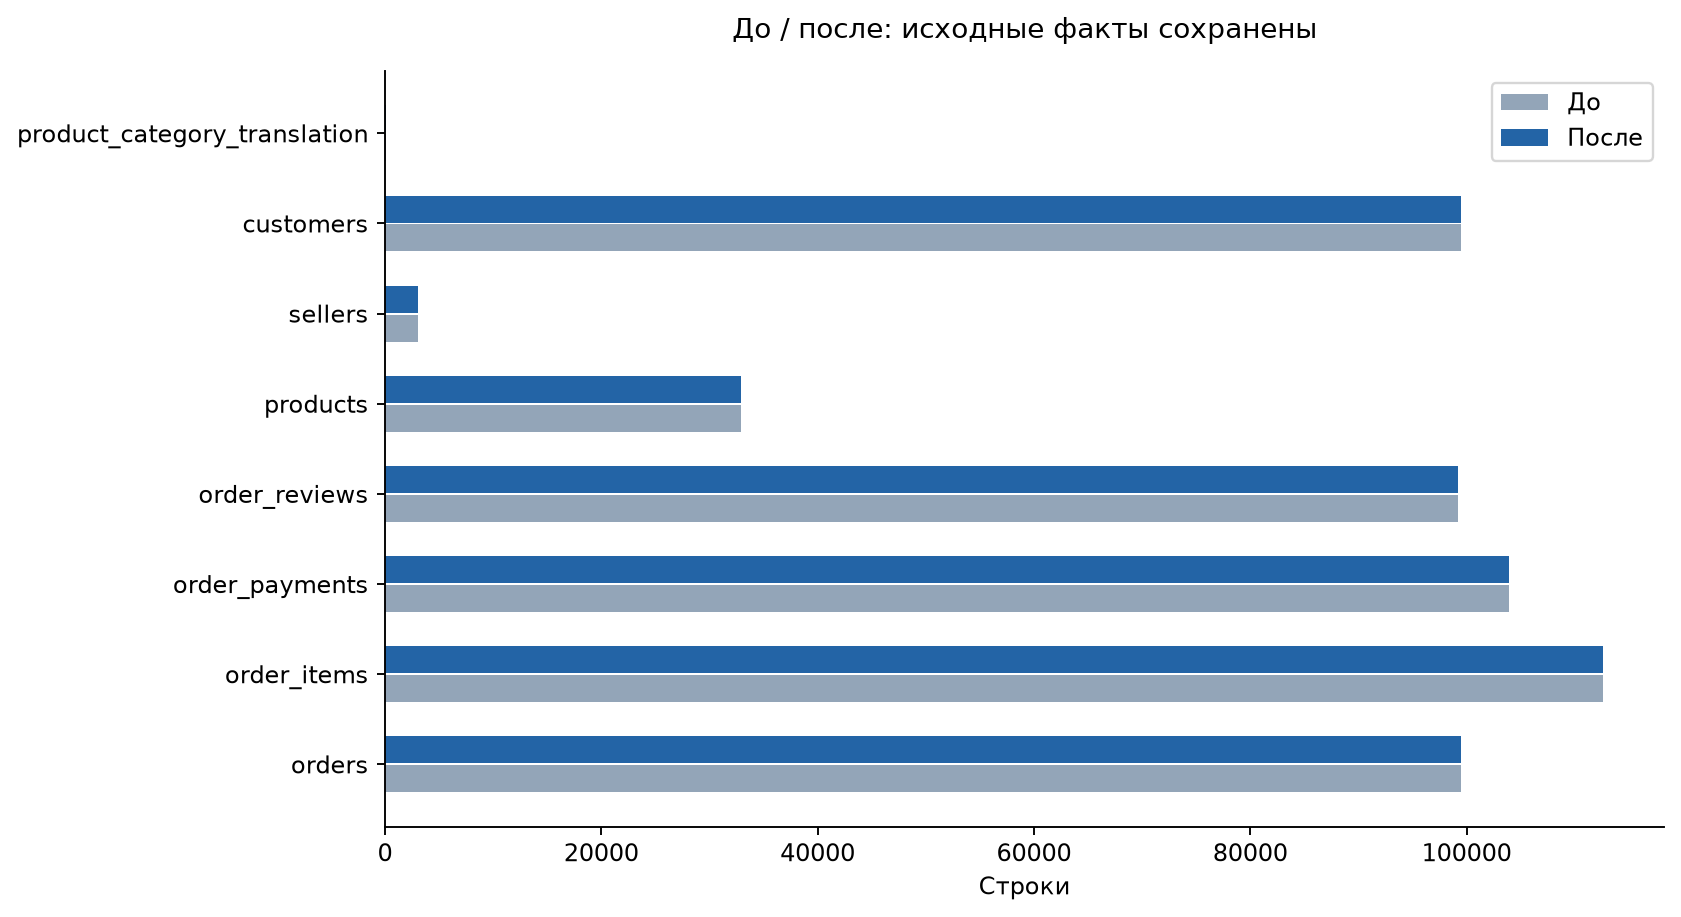

**Результат предобработки:** строки не удалялись; типы приведены, суммы и связи проверены. Не заявляем, что все пропуски исчезли.

{"status": "passed", "source_files_unchanged": true, "preprocessing_rows_removed": 0, "parse_errors": 0, "charts": 10}


In [12]:
fig,ax=plt.subplots(figsize=(10,5.5))
y=np.arange(len(comparison));ax.barh(y-.16,comparison.rows_before,height=.30,color=GRAY,label='До');ax.barh(y+.16,comparison.rows_after,height=.30,color=BLUE,label='После')
ax.set_yticks(y);ax.set_yticklabels(comparison.table);ax.set_xlabel('Строки');ax.set_title('До / после: исходные факты сохранены');ax.legend()
savefig(fig,'10_before_after_rows','**Результат предобработки:** строки не удалялись; типы приведены, суммы и связи проверены. Не заявляем, что все пропуски исчезли.')
hashes_after={name:hashlib.sha256((DATA/file).read_bytes()).hexdigest() for name,file in FILES.items()}
assert hashes_before==hashes_after, 'Исходные файлы изменились'
metrics={
 'status':'passed','scope':'local_csv_research_not_deployed_core','source_hashes':hashes_before,
 'source_rows':{name:len(df) for name,df in raw.items()},'source_files_unchanged':True,
 'preprocessing_rows_removed':int(comparison.rows_removed.sum()),'parse_errors':int(parse_log.errors.sum()),
 'delivered_orders':len(delivered),'revenue_cents':revenue,'average_check':str(aov),
 'customers':people,'repeat_customers':repeat,'repeat_percent':round(repeat/people*100,4),
 'categories':len(by_category),'missing_product_categories':int(products.is_missing_category.sum()),
 'untranslated_categories':untranslated.category_key.tolist(),
 'orders_without_items':int(no_items.sum()),'orders_without_payments':int(no_payments.sum()),
 'payment_mismatches_exact':int(mismatch.sum()),
 'payment_mismatches_gt_one_cent':int((both & summary.payment_delta_cents.abs().gt(1).fillna(False)).sum()),
 'delivery':delivery_metrics,'charts':len(artifacts),
 'controls':checks.to_dict(orient='records'),
 'environment':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'matplotlib':matplotlib.__version__}}
(OUT/'metrics.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2,default=str)+'\n',encoding='utf-8')
(OUT/'figure_manifest.json').write_text(json.dumps(artifacts,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
print(json.dumps({k:metrics[k] for k in ['status','source_files_unchanged','preprocessing_rows_removed','parse_errors','charts']},ensure_ascii=False))

## 13. Выводы для чек-поинта и следующие шаги

**Уже сделано здесь:** изучены восемь таблиц, проверены зерно/ключи/ссылки,
созданы типизированные копии и безопасные агрегаты, повторно проверены строки и деньги,
получены контрольные показатели и графики. Хеши CSV до/после совпадают.

**Далее реализовать:**
1. Перенести согласованные преобразования в SQL `core` с PK/FK и документированными типами.
2. Реализовать build с транзакцией и `ON_ERROR_STOP`, контрольными assertions и повторным запуском.
3. Создать mart с едиными контрактами пяти показателей и отвечать из модели, а не из CSV.
4. Добавить отчёты качества, lineage и каталог загрузок.
5. Подготовить новые вопросы, дашборд-концепцию и историю развития.
6. Только отдельно — ML-эксперимент с доступными во времени признаками и baseline.

**Не доказано:** причины финансовых расхождений; вина отдельного продавца/перевозчика;
причинный эффект опоздания; рост прибыли или удержания после проекта; качество ML.
Нет геолокации и полного журнала событий. Текущие статусы не восстанавливают прошлое знание системы.

**Материал для STAR:** результат исследования — проверяемые определения, наблюдения,
прототип преобразований и план реализации. Его нельзя подменять утверждением,
что промышленная система уже развёрнута или улучшила бизнес-показатели.

**Происхождение:** условия `docs/handout.md`, вопросы `docs/tasks.md`, локальные CSV;
новый каталог сохранён в `docs/knowledge_sources/`, спорные рекомендации разобраны
в `docs/checkpoint/SOURCE_REVIEW.md`. Порядок EDA заимствован как идея, код написан для текущего набора.